In [1]:
# imports
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.gridspec import SubplotSpec
import matplotlib.ticker as ticker
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.legend_handler import HandlerTuple
import scienceplots
plt.style.use(['science', 'nature', 'grid'])
from cycler import cycler
mpl.rcParams['axes.prop_cycle'] = cycler(color=['b', 'g', 'r', 'c', 'm', 'y', 'k'])

import numpy as np

import jax
import jax.numpy as jnp
import jax.random as jr
from jax.flatten_util import ravel_pytree
import optax
import os
import equinox as eqx
import pandas as pd
from tqdm import tqdm


from src.bnn import Problem, build_F
from src.vanilla import Vanilla
from src.gaussian import GaussianBNN
from src.cauchy import CauchyBNN
from src.gsbl import GSBLBNN, GSBLBNN_CombinedOptimization

In [2]:
mpl.rcParams['axes.labelsize'] = 9
mpl.rcParams['font.size'] = 9
mpl.rcParams['xtick.labelsize'] = 9
mpl.rcParams['ytick.labelsize'] = 9

# Denoising a piecewise-constant function

In [3]:
# Create the model and the data
# Note: data is the same as for the training process, as we used the same random seed for the data generation
def f(x):
    return jnp.where(
        x < -0.5, -0.5, jnp.where(
            x < 0.5, 0.5, jnp.where(
                x < 0.7, -1.5, 0.0)
            )
        )

# Parameter
M = 50
n_disc = 128
SEED = 42
noise_level = [0.01, 0.05, 0.1, 0.2]

# Data generation -- the data key is INDEPENDENT of the network init key
data_key = jr.PRNGKey(SEED + 1000)

x_obs = jnp.linspace(-1.0, 1.0, M).reshape(-1, 1)
x_extrapolation = jnp.linspace(-1.2, 1.2, 512).reshape(-1, 1)
x_fine = jnp.linspace(-1.0, 1.0, 512).reshape(-1, 1)
y_fine = f(x_fine)

y_obs_vec = []
for noise in noise_level:
    y_obs = f(x_obs) + noise * jr.normal(data_key, (M, 1))
    y_obs_vec.append(y_obs)

In [4]:
# Common NN settings
N_ENSEMBLES = 50
width = [1, 64, 64, 64, 64, 1]
activation = jax.nn.tanh
optimizer_pretraining = optax.contrib.muon(learning_rate=1e-3)
optimizer_name = 'muon'
lr_schedule = 1e-3
N_EPOCHS_PRE = 500
N_EPOCHS_LBFGS = 1_500

common = dict(
    width=width, activation=activation, seed=SEED,
    optimizer_pretraining=optimizer_pretraining,
    n_epochs_pre_training=N_EPOCHS_PRE, n_epochs_lbfgs=N_EPOCHS_LBFGS
)

dirname = 'out/PiecewiseConstant_Noisy/'
fig_dirname = 'out/figures/PiecewiseConstant_Noisy/'
if not os.path.exists(fig_dirname):
    os.makedirs(fig_dirname)

In [5]:
vartheta1 = 100.0
kappa = 10.0
c_bias = 2.0
n_inner = 10
r = -1.0 

In [6]:
def plot_routine(model_name, noise_, initializer, vartheta1_=100.0, kappa_=10.0, beta_=1.0, savefig=False, n_members=5, band=0.9, y_blur=None, figsize=(6.8/3, 2.5), ax_band=None, ax_member=None):
    # Load the results
    if model_name == 'Gaussian':
        model_list = [GaussianBNN(**common, gauss_std=1.0) for _ in range(N_ENSEMBLES)]
        filename = lambda i: os.path.join(dirname, f'{model_name}/{initializer}/{optimizer_name}_noise_{noise_}/Ensemble_{i}/{model_name}_model_{i}.csv')
    elif model_name == 'Cauchy':
        model_list = [CauchyBNN(**common, cauchy_scale=1.0) for _ in range(N_ENSEMBLES)]
        filename = lambda i: os.path.join(dirname, f'{model_name}/{initializer}/{optimizer_name}_noise_{noise_}/Ensemble_{i}/{model_name}_model_{i}.csv')
    elif model_name == 'GSBL_Independent':
        model_list = [GSBLBNN(**common, vartheta1=vartheta1_, kappa=kappa_, c_bias=c_bias, n_inner=n_inner, r=r, beta=beta_) for _ in range(N_ENSEMBLES)]
        filename = lambda i: os.path.join(dirname, f'{model_name}/{initializer}/{optimizer_name}_kappa{kappa_}_beta{beta_}_vartheta1_{vartheta1_}_noise_{noise_}/Ensemble_{i}/{model_name}_model_{i}.csv')
    elif model_name == 'GSBL_Shared':
        model_list = [GSBLBNN(**common, vartheta1=vartheta1_, kappa=kappa_, c_bias=c_bias, n_inner=n_inner, r=r, beta=beta_) for _ in range(N_ENSEMBLES)]
        filename = lambda i: os.path.join(dirname, f'{model_name}/{initializer}/{optimizer_name}_kappa{kappa_}_beta{beta_}_vartheta1_{vartheta1_}_noise_{noise_}/Ensemble_{i}/{model_name}_model_{i}.csv')
    elif model_name == 'GSBL_Shared_CombinedOptimization':
        model_list = [GSBLBNN_CombinedOptimization(**common, vartheta1=vartheta1_, kappa=kappa_, c_bias=c_bias, n_inner=1, r=r, beta=beta_) for _ in range(N_ENSEMBLES)]
        filename = lambda i: os.path.join(dirname, f'{model_name}/{initializer}/{optimizer_name}_kappa{kappa_}_beta{beta_}_vartheta1_{vartheta1_}_noise_{noise_}/Ensemble_{i}/{model_name}_model_{i}.csv')
    else:
        raise ValueError(f"Unknown model name: {model_name}")
    for i, model in enumerate(model_list):
            model.load(filename(i))
    
    # Predict on interior grid and calculate relative L1 error for each ensemble member
    y_pred_interpolation = jnp.stack([model.evaluate(x_fine) for model in model_list], axis=0)
    rel_l1_mask = jnp.sum(jnp.abs(y_pred_interpolation - f(x_fine)), axis=1) / jnp.sum(jnp.abs(f(x_fine)), axis=0)

    # Mask which ensembles to throw away (the worst performing ones)
    mask = jnp.argsort(rel_l1_mask.reshape(-1))[:N_ENSEMBLES]

    # Only take those ensembles that are not thrown away
    model_list = [model_list[i] for i in mask]
    y_pred_extrapolation = jnp.stack([model.evaluate(x_extrapolation) for model in model_list], axis=0)
    y_pred_interpolation = y_pred_interpolation[mask]
    predictive_mean_interpolation = jnp.mean(y_pred_interpolation, axis=0)
    rel_l1_of_mean = jnp.sum(jnp.abs(predictive_mean_interpolation - f(x_fine))) / jnp.sum(jnp.abs(f(x_fine)))
    mean_of_rel_l1_errors = jnp.mean(rel_l1_mask[mask])
    median_of_rel_l1_errors = jnp.median(rel_l1_mask[mask])
    variance_of_rel_l1_errors = jnp.var(rel_l1_mask[mask], ddof=1)
    
    M_eff = y_pred_interpolation.shape[0]
    mae = jnp.mean(jnp.abs(y_pred_interpolation - f(x_fine)), axis=0)                        # (N, 1)
    spread = jnp.mean(jnp.abs(y_pred_interpolation[:, None] - y_pred_interpolation[None, :]), axis=(0, 1))  # (N, 1)
    CRPS = jnp.mean(mae - 0.5 * spread) # Maybe use the unbiased one with CRPS = M_eff / (M_eff - 1) * spread



    wall_clock_times = [model.wall_clock_time[-1] for model in model_list]
    median_of_wall_clock_times = jnp.median(jnp.array(wall_clock_times))

    print(f"Model: {model_name}, Noise: {noise_}, Relative L1 error of predictive mean: {rel_l1_of_mean:.6f}, Mean of relative L1 errors of ensemble members: {mean_of_rel_l1_errors:.6f}, Median of relative L1 errors of ensemble members: {median_of_rel_l1_errors:.6f}, Median of wall clock times: {median_of_wall_clock_times:.6f}, Variance of relative L1 errors of ensemble members: {variance_of_rel_l1_errors:.6f}, CRPS: {CRPS:.6f}")

    # Save the three error measures into a txt file
    if not os.path.exists(os.path.join(fig_dirname, model_name)):
        os.makedirs(os.path.join(fig_dirname, model_name))
    if model_name in ['GSBL_Independent', 'GSBL_Shared', 'GSBL_Shared_CombinedOptimization']:
        filename = os.path.join(fig_dirname, f'{model_name}/{optimizer_name}_kappa{kappa_}_beta{beta_}_vartheta1_{vartheta1_}_noise_{noise_}_init_{initializer}_error_measures.txt')
    else:
        filename = os.path.join(fig_dirname, f'{model_name}/{optimizer_name}_noise_{noise_}_init_{initializer}_error_measures.txt')
    with open(filename, 'w') as file:
        file.write(f"Relative L1 error of predictive mean: {rel_l1_of_mean:.6f}\n")
        file.write(f"Mean of relative L1 errors of ensemble members: {mean_of_rel_l1_errors:.6f}\n")
        file.write(f"Median of relative L1 errors of ensemble members: {median_of_rel_l1_errors:.6f}\n")
        file.write(f"Variance of relative L1 errors of ensemble members: {variance_of_rel_l1_errors:.6f}\n")
        file.write(f"CRPS: {CRPS:.6f}\n")
        file.write(f"Median of wall clock times: {median_of_wall_clock_times:.6f}\n")

    # Uncertainty Intervals
    # Draw into the given axes if there is one (grid figure), otherwise create a standalone figure
    own_fig_band = ax_band is None
    fig_band, axs_band = plt.subplots(figsize=figsize) if own_fig_band else (ax_band.figure, ax_band)
    axs_band.plot(x_fine, y_fine, '--', color='black', label=r'Truth $u^\dagger$')
    axs_band.scatter(x_obs, y_obs_vec[noise_level.index(noise_)], color='red', marker='o', s=4, label='Noisy observations')
    if y_blur is not None:
        axs_band.plot(x_fine, y_blur, color='orange', linestyle='--', label='Blurred Truth')
    axs_band.fill_between(x_extrapolation.flatten(), jnp.percentile(y_pred_extrapolation, 100 * (0.5 - band/2), axis=0).flatten(), jnp.percentile(y_pred_extrapolation, 100 * (0.5 + band/2), axis=0).flatten(), color='blue', alpha=0.2, label=f'${100*band:g}\\%$ Credible interval')
    axs_band.plot(x_extrapolation, jnp.mean(y_pred_extrapolation, axis=0), color='blue', label='Predicted mean')

    axs_band.set_xlabel('x'); axs_band.set_ylabel('u'); axs_band.grid(True)
    axs_band.set_ylim(y_fine.min() - 0.5, y_fine.max() + 0.5)

    if own_fig_band:
        fig_band.tight_layout()
        if savefig == True:
            if model_name in ['GSBL_Independent', 'GSBL_Shared', 'GSBL_Shared_CombinedOptimization']:
                fig_band.savefig(os.path.join(fig_dirname, f'{model_name}/{optimizer_name}_kappa{kappa_}_beta{beta_}_vartheta1_{vartheta1_}_noise_{noise_}_credibility_band_{model_name}_init_{initializer}.pdf'))
            else:
                fig_band.savefig(os.path.join(fig_dirname, f'{model_name}/{optimizer_name}_noise_{noise_}_credibility_band_{model_name}_init_{initializer}.pdf'))
        fig_band.show()

    # Ensemble Members Plot
    own_fig_member = ax_member is None
    fig_member, axs_member = plt.subplots(figsize=figsize) if own_fig_member else (ax_member.figure, ax_member)
    axs_member.plot(x_fine, y_fine, '--', color='black', label=r'Truth $u^\dagger$')
    axs_member.scatter(x_obs, y_obs_vec[noise_level.index(noise_)], color='red', marker='o', s=4, label='Noisy observations')
    if y_blur is not None:
        axs_member.plot(x_fine, y_blur, color='orange', linestyle='--', label='Blurred Truth')
    plot_idx = jr.choice(jr.PRNGKey(SEED+10), N_ENSEMBLES, (n_members,), replace=False)
    [axs_member.plot(x_extrapolation, y_pred_extrapolation[idx], label=f'Ensemble member {idx}', alpha=0.7) for idx in plot_idx]

    axs_member.set_xlabel('x'); axs_member.set_ylabel('u'); axs_member.grid(True)
    axs_member.set_ylim(y_fine.min() - 0.5, y_fine.max() + 0.5)

    if own_fig_member:
        fig_member.tight_layout()
        if savefig == True:
            if model_name in ['GSBL_Independent', 'GSBL_Shared', 'GSBL_Shared_CombinedOptimization']:
                fig_member.savefig(os.path.join(fig_dirname, f'{model_name}/{optimizer_name}_kappa{kappa_}_beta{beta_}_vartheta1_{vartheta1_}_noise_{noise_}_member_plots_{model_name}_init_{initializer}.pdf'))
            else:
                fig_member.savefig(os.path.join(fig_dirname, f'{model_name}/{optimizer_name}_noise_{noise_}_member_plots_{model_name}_init_{initializer}.pdf'))
        fig_member.show()

In [7]:
def make_grid(n_rows, n_cols, width=6.8):
    # Empty grid of axes with shared x and y; the height is a first guess that finish_grid corrects
    fig, axs = plt.subplots(n_rows, n_cols, figsize=(width, width / n_cols * 0.8 * n_rows + 0.7), sharex=True, sharey=True, squeeze=False, layout='constrained')
    return fig, axs

def finish_grid(fig, axs, col_titles=None, row_titles=None, legend_ncol=None, panel_aspect=0.8, savefig=False, filename=None):
    # Keep the x labels only in the last row and the y labels only in the first column
    for ax in axs.flat:
        ax.label_outer()
    if col_titles is not None:
        for ax, title in zip(axs[0, :], col_titles):
            ax.set_title(title)
    if row_titles is not None:
        for ax, title in zip(axs[:, 0], row_titles):
            ax.annotate(title, xy=(0, 0.5), xycoords=ax.yaxis.label, xytext=(-ax.yaxis.labelpad - 4, 0), textcoords='offset points', ha='right', va='center', rotation=90)
    # Legend centred on the axes columns, not on the figure (the y label and row titles make the left margin wider)
    if legend_ncol is not None:
        handles, labels = axs[0, 0].get_legend_handles_labels()
        fig.canvas.draw()   # run the constrained layout once, so that the axes positions are final
        x_left, x_right = axs[0, 0].get_position().x0, axs[0, -1].get_position().x1
        fig.legend(handles, labels, loc='lower center', bbox_to_anchor=((x_left + x_right) / 2, 1.0), ncol=legend_ncol, frameon=False)
    # Rescale the figure height such that the axes boxes get the aspect ratio panel_aspect (height / width).
    # Titles, labels, tick labels and legend take a fixed amount of space, so the figure height from make_grid is only a guess.
    n_rows = axs.shape[0]
    for _ in range(3):
        fig.canvas.draw()
        pos = axs[0, 0].get_position()
        ax_w, ax_h = pos.width * fig.get_figwidth(), pos.height * fig.get_figheight()
        fig.set_figheight(fig.get_figheight() + n_rows * (panel_aspect * ax_w - ax_h))
    print(f'Panel size: {ax_w:.3f} x {ax_h:.3f} in')
    if savefig == True:
        fig.savefig(filename)
    fig.show()

Model: Gaussian, Noise: 0.1, Relative L1 error of predictive mean: 0.127585, Mean of relative L1 errors of ensemble members: 0.129182, Median of relative L1 errors of ensemble members: 0.128420, Median of wall clock times: 7.992020, Variance of relative L1 errors of ensemble members: 0.000035, CRPS: 0.061311
Model: Gaussian, Noise: 0.1, Relative L1 error of predictive mean: 0.124318, Mean of relative L1 errors of ensemble members: 0.124631, Median of relative L1 errors of ensemble members: 0.124188, Median of wall clock times: 9.276110, Variance of relative L1 errors of ensemble members: 0.000002, CRPS: 0.062511
Model: Cauchy, Noise: 0.1, Relative L1 error of predictive mean: 0.116030, Mean of relative L1 errors of ensemble members: 0.128455, Median of relative L1 errors of ensemble members: 0.113884, Median of wall clock times: 8.448880, Variance of relative L1 errors of ensemble members: 0.001119, CRPS: 0.047686
Model: Cauchy, Noise: 0.1, Relative L1 error of predictive mean: 1.49042

/var/folders/mm/p6fstv8949vbtxn89ljjbk8w0000gp/T/ipykernel_31088/2725333759.py:33: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


Panel size: 1.943 x 1.554 in
Model: GSBL_Independent, Noise: 0.1, Relative L1 error of predictive mean: 0.155312, Mean of relative L1 errors of ensemble members: 0.263604, Median of relative L1 errors of ensemble members: 0.196862, Median of wall clock times: 12.514900, Variance of relative L1 errors of ensemble members: 0.034426, CRPS: 0.045299
Model: GSBL_Shared_CombinedOptimization, Noise: 0.1, Relative L1 error of predictive mean: 0.114763, Mean of relative L1 errors of ensemble members: 0.178395, Median of relative L1 errors of ensemble members: 0.155130, Median of wall clock times: 5.582005, Variance of relative L1 errors of ensemble members: 0.010920, CRPS: 0.040412
Model: GSBL_Shared, Noise: 0.1, Relative L1 error of predictive mean: 0.110806, Mean of relative L1 errors of ensemble members: 0.166143, Median of relative L1 errors of ensemble members: 0.144667, Median of wall clock times: 10.565451, Variance of relative L1 errors of ensemble members: 0.010944, CRPS: 0.037768
Pane

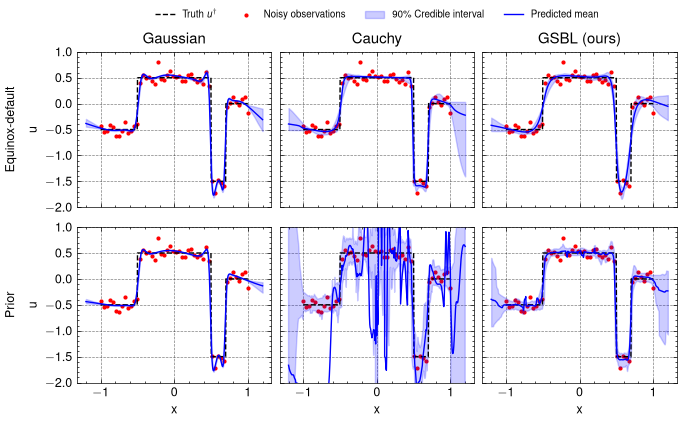

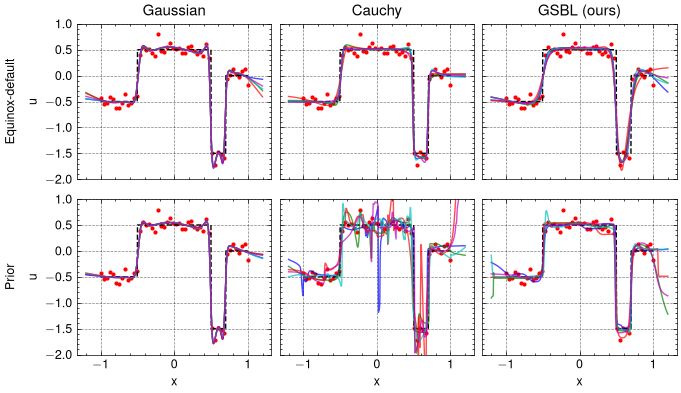

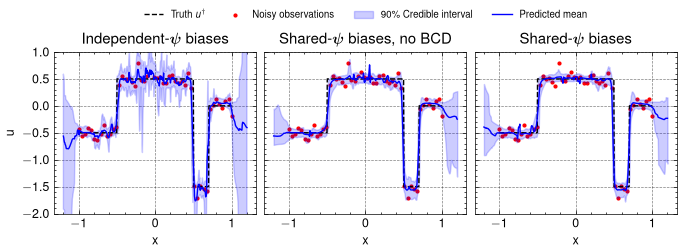

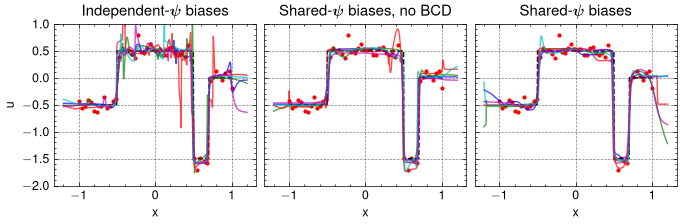

In [8]:
noise = 0.1
col_titles = ['Gaussian', 'Cauchy', 'GSBL (ours)']
row_titles = ['Equinox-default', 'Prior']

# Comparison figure: one call per panel fills both the credibility-band grid and the member grid
fig_band, axs_band = make_grid(2, 3)
fig_member, axs_member = make_grid(2, 3)
plot_routine('Gaussian', noise, initializer='Default', ax_band=axs_band[0, 0], ax_member=axs_member[0, 0])
plot_routine('Gaussian', noise, initializer='Gaussian', ax_band=axs_band[1, 0], ax_member=axs_member[1, 0])
plot_routine('Cauchy', noise, initializer='Default', ax_band=axs_band[0, 1], ax_member=axs_member[0, 1])
plot_routine('Cauchy', noise, initializer='Cauchy', ax_band=axs_band[1, 1], ax_member=axs_member[1, 1])
plot_routine('GSBL_Shared', noise, initializer='Default', vartheta1_=vartheta1, kappa_=kappa, beta_=1.0, ax_band=axs_band[0, 2], ax_member=axs_member[0, 2])
plot_routine('GSBL_Shared', noise, initializer='GG', vartheta1_=vartheta1, kappa_=kappa, beta_=1.0, ax_band=axs_band[1, 2], ax_member=axs_member[1, 2])
finish_grid(fig_band, axs_band, col_titles=col_titles, row_titles=row_titles, legend_ncol=4, savefig=True, filename=os.path.join(fig_dirname, f'{optimizer_name}_noise_{noise}_CompareBNNs_credibility_band.pdf'))
finish_grid(fig_member, axs_member, col_titles=col_titles, row_titles=row_titles, savefig=True, filename=os.path.join(fig_dirname, f'{optimizer_name}_noise_{noise}_CompareBNNs_member_plots.pdf'))


# GSBL comparison: independent biases vs. shared biases without and with BCD
noise = 0.1
col_titles = [r'Independent-$\boldsymbol{\psi}$ biases', r'Shared-$\boldsymbol{\psi}$ biases, no BCD', r'Shared-$\boldsymbol{\psi}$ biases']

fig_band, axs_band = make_grid(1, 3)
fig_member, axs_member = make_grid(1, 3)
plot_routine('GSBL_Independent', noise, initializer='GG', vartheta1_=vartheta1, kappa_=kappa, beta_=1.0, ax_band=axs_band[0, 0], ax_member=axs_member[0, 0])
plot_routine('GSBL_Shared_CombinedOptimization', noise, initializer='GG', vartheta1_=vartheta1, kappa_=kappa, beta_=1.0, ax_band=axs_band[0, 1], ax_member=axs_member[0, 1])
plot_routine('GSBL_Shared', noise, initializer='GG', vartheta1_=vartheta1, kappa_=kappa, beta_=1.0, ax_band=axs_band[0, 2], ax_member=axs_member[0, 2])
finish_grid(fig_band, axs_band, col_titles=col_titles, legend_ncol=4, savefig=True, filename=os.path.join(fig_dirname, f'{optimizer_name}_kappa{kappa}_beta1.0_vartheta1_{vartheta1}_noise_{noise}_GSBLComparison_credibility_band.pdf'))
finish_grid(fig_member, axs_member, col_titles=col_titles, savefig=True, filename=os.path.join(fig_dirname, f'{optimizer_name}_kappa{kappa}_beta1.0_vartheta1_{vartheta1}_noise_{noise}_GSBLComparison_member_plots.pdf'))

### Noise Analysis

/var/folders/mm/p6fstv8949vbtxn89ljjbk8w0000gp/T/ipykernel_31088/1282844102.py:82: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


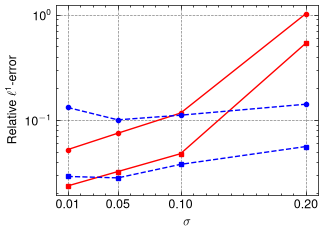

In [9]:
# Simplified version of the plot above: only Cauchy vs. shared GSBL over the noise level.
# Solid line: mean of the relative L1 errors of the (kept) ensemble members, with a band spanning
# the full min-max range of those errors. Dashed line: relative L1 error of the predictive mean.
beta = 1.0
Cauchy_initializer = 'Default'
savefig = True

colors = {'Cauchy': 'r', 'GSBL_Shared': 'b'}
linestyles = {'Cauchy': '-', 'GSBL_Shared': '--'}
marker = {'rel_l1': 'o', 'CRPS': 's'}
labels = {'Cauchy': 'Cauchy', 'GSBL_Shared': 'GSBL'}

fig, axs = plt.subplots(figsize=(6.8/2, 2.5))
for model_name in ['Cauchy', 'GSBL_Shared']:
    initializer = Cauchy_initializer if model_name == 'Cauchy' else 'GG'

    quantile_05_rel_l1_errors_vec, quantile_95_rel_l1_errors_vec = [], []
    rel_l1_of_mean_vec, mean_of_rel_l1_errors_vec, CRPS_vec = [], [], []
    for noise_ in noise_level:
        if model_name == 'Cauchy':
            model_list = [CauchyBNN(**common, cauchy_scale=1.0) for _ in range(N_ENSEMBLES)]
            filename = lambda i: os.path.join(dirname, f'{model_name}/{initializer}/{optimizer_name}_noise_{noise_}/Ensemble_{i}/{model_name}_model_{i}.csv')
        elif model_name == 'GSBL_Shared':
            model_list = [GSBLBNN(**common, vartheta1=vartheta1, kappa=kappa, c_bias=c_bias, n_inner=n_inner, r=r, beta=beta) for _ in range(N_ENSEMBLES)]
            filename = lambda i: os.path.join(dirname, f'{model_name}/{initializer}/{optimizer_name}_kappa{kappa}_beta{beta}_vartheta1_{vartheta1}_noise_{noise_}/Ensemble_{i}/{model_name}_model_{i}.csv')
        else:
            raise ValueError(f"Unknown model name: {model_name}")

        for i, model in enumerate(model_list):
            model.load(filename(i))

        # Predict on interior grid and calculate relative L1 error for each ensemble member
        y_pred_interpolation = jnp.stack([model.evaluate(x_fine) for model in model_list], axis=0)
        rel_l1_mask = jnp.sum(jnp.abs(y_pred_interpolation - f(x_fine)), axis=1) / jnp.sum(jnp.abs(f(x_fine)), axis=0)

        # Mask which ensembles to throw away (the worst performing ones)
        mask = jnp.argsort(rel_l1_mask.reshape(-1))[:N_ENSEMBLES]

        # Only take those ensembles that are not thrown away
        rel_l1_errors = rel_l1_mask[mask].reshape(-1)
        predictive_mean_interpolation = jnp.mean(y_pred_interpolation[mask], axis=0)
        rel_l1_of_mean = jnp.sum(jnp.abs(predictive_mean_interpolation - f(x_fine))) / jnp.sum(jnp.abs(f(x_fine)))

        rel_l1_of_mean_vec.append(float(rel_l1_of_mean))
        mean_of_rel_l1_errors_vec.append(float(jnp.mean(rel_l1_errors)))
        quantile_05_rel_l1_errors_vec.append(float(jnp.quantile(rel_l1_errors, 0.05)))
        quantile_95_rel_l1_errors_vec.append(float(jnp.quantile(rel_l1_errors, 0.95)))

        mae = jnp.mean(jnp.abs(y_pred_interpolation - f(x_fine)), axis=0)                        # (N, 1)
        spread = jnp.mean(jnp.abs(y_pred_interpolation[:, None] - y_pred_interpolation[None, :]), axis=(0, 1))  # (N, 1)
        CRPS = jnp.mean(mae - 0.5 * spread) # Maybe use the unbiased one with CRPS = M_eff / (M_eff - 1) * spread
        CRPS_vec.append(float(CRPS))

    # axs.fill_between(noise_level, quantile_05_rel_l1_errors_vec, quantile_95_rel_l1_errors_vec, color=colors[model_name], alpha=0.2)
    axs.semilogy(noise_level, rel_l1_of_mean_vec, linestyles[model_name], marker=marker['rel_l1'], color=colors[model_name])
    axs.semilogy(noise_level, CRPS_vec, linestyles[model_name], marker=marker['CRPS'], color=colors[model_name])


axs.set_xlabel(r'$\sigma$'); axs.set_ylabel('Relative $\\ell^1$-error'); axs.grid(True)

# colour encodes the model, line style encodes the quantity
handles = [Line2D([], [], color=colors[m], linestyle=linestyles[m], lw=1.2) for m in ['Cauchy', 'GSBL_Shared']]
handles += [
    Line2D([], [], color='0.25', marker=marker['rel_l1'], ls=''),
    Line2D([], [], color='0.25', marker=marker['CRPS'], ls=''),]
legend_labels = [
    labels['Cauchy'], labels['GSBL_Shared'], 
    'Predictive mean', 'CRPS'
]
axs.set_xticks(noise_level)

leg = axs.legend(
    handles, legend_labels, handler_map={tuple: HandlerTuple(ndivide=1, pad=0)},
    fontsize=6, loc='lower center', bbox_to_anchor=(0.5, 1.0), ncol=2,
    frameon=False, columnspacing=1.0, handlelength=2.0
)
leg.set_in_layout(False)   # tight_layout sizes the axes as if there were no legend
axs.set_xticks(noise_level)
fig.tight_layout()
if savefig == True:
    fig.savefig(os.path.join(fig_dirname, f'{optimizer_name}_kappa{kappa}_beta{beta}_vartheta1_{vartheta1}_noise_comparison_Cauchy_init_{Cauchy_initializer}_vs_GSBL_Shared.pdf'), bbox_extra_artists=[leg])
fig.show()

### Coverage

/var/folders/mm/p6fstv8949vbtxn89ljjbk8w0000gp/T/ipykernel_31088/438279166.py:45: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "-o" (-> marker='o'). The keyword argument will take precedence.
  axs.plot(coverage_level, coverage_vec, '-o', color=colors[model_name], label=labels[model_name], marker=markers[model_name])


Model: Cauchy, Noise: 0.1, MSE of coverage: 0.132568
Model: GSBL_Shared, Noise: 0.1, MSE of coverage: 0.041209


/var/folders/mm/p6fstv8949vbtxn89ljjbk8w0000gp/T/ipykernel_31088/438279166.py:61: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


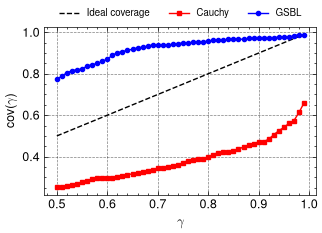

In [10]:
beta = 1.0
Default_initializer = 'Default'
savefig = True

colors = {'Cauchy': 'r', 'GSBL_Shared': 'b'}
labels = {'Cauchy': 'Cauchy', 'GSBL_Shared': 'GSBL'}
markers = {'Cauchy': 's', 'GSBL_Shared': 'o'}

coverage_level = jnp.linspace(0.50, 0.99, 50)
fig, axs = plt.subplots(figsize=(6.8/2, 2.5))

axs.plot(coverage_level, coverage_level, '--', color='black', label='Ideal coverage')

noise_ = 0.1
for model_name in ['Cauchy', 'GSBL_Shared']:
    if noise_ == 0.2 and model_name == 'Cauchy':
        continue # Skip this combination, as the Cauchy model diverges for this noise level
    initializer = Default_initializer if model_name in ['Cauchy'] else 'GG'

    quantile_05_rel_l1_errors_vec, quantile_95_rel_l1_errors_vec = [], []
    coverage_vec = []
    if model_name in ['Gaussian', 'Cauchy']:
        model_list = [CauchyBNN(**common, cauchy_scale=1.0) for _ in range(N_ENSEMBLES)]
        filename = lambda i: os.path.join(dirname, f'{model_name}/{initializer}/{optimizer_name}_noise_{noise_}/Ensemble_{i}/{model_name}_model_{i}.csv')
    elif model_name == 'GSBL_Shared':
        model_list = [GSBLBNN(**common, vartheta1=vartheta1, kappa=kappa, c_bias=c_bias, n_inner=n_inner, r=r, beta=beta) for _ in range(N_ENSEMBLES)]
        filename = lambda i: os.path.join(dirname, f'{model_name}/{initializer}/{optimizer_name}_kappa{kappa}_beta{beta}_vartheta1_{vartheta1}_noise_{noise_}/Ensemble_{i}/{model_name}_model_{i}.csv')
    else:
        raise ValueError(f"Unknown model name: {model_name}")

    for i, model in enumerate(model_list):
        model.load(filename(i))

    for level in coverage_level:

        # Predict on interior grid and calculate relative L1 error for each ensemble member
        y_pred_interpolation = jnp.stack([model.evaluate(x_fine) for model in model_list], axis=0)


        lo, hi = (1 - level) / 2, 1 - (1 - level) / 2
        q_lo, q_hi = jnp.quantile(y_pred_interpolation, lo, axis=0), jnp.quantile(y_pred_interpolation, hi, axis=0)
        covered = (y_fine >= q_lo) & (y_fine <= q_hi)
        coverage_vec.append(jnp.mean(covered))

    axs.plot(coverage_level, coverage_vec, '-o', color=colors[model_name], label=labels[model_name], marker=markers[model_name])

    mse_coverage = jnp.mean((jnp.array(coverage_vec) - coverage_level) ** 2)
    print(f"Model: {model_name}, Noise: {noise_}, MSE of coverage: {mse_coverage:.6f}")

leg = axs.legend(ncol=3, loc='lower center', bbox_to_anchor=(0.5, 1.0), frameon=False)
axs.set_xlabel('$\\gamma$'); axs.set_ylabel(f'$\\mathrm{{cov}}(\\gamma)$'); axs.grid(True)

fig.tight_layout()
if savefig == True:
    fig.savefig(
        os.path.join(fig_dirname, 'Coverage_Cauchy_vs_GSBL_Shared.pdf'),
        bbox_inches='tight',
        bbox_extra_artists=[leg],
        pad_inches=0.02,
    )
fig.show()

### Parameter Comparison (shared GSBL)

In [11]:
# Parameter comparison of the shared GSBL prior: the three error measures on the (vartheta1 x kappa) grid for
# beta in {0.5, 1.0} and the noise levels sigma in {0.05, 0.1, 0.2}.
model_name = 'GSBL_Shared'
initializer = 'GG'
beta_vec_cmp = [0.5, 1.0]
noise_vec_cmp = [0.05, 0.1, 0.2]
vartheta1_vec_cmp = [0.1, 1.0, 10.0, 100.0, 1_000.0]
kappa_vec_cmp = [0.1, 1.0, 10.0, 100.0, 1_000.0]
error_measures = ['Relative L1 error of predictive mean',
                  'Mean of relative L1 errors of ensemble members',
                  'Median of relative L1 errors of ensemble members']

# errors[measure][beta, noise] is the (vartheta1 x kappa) table of one error measure
errors = {measure: {(beta_, noise_): np.full((len(vartheta1_vec_cmp), len(kappa_vec_cmp)), np.nan)
                    for beta_ in beta_vec_cmp for noise_ in noise_vec_cmp} for measure in error_measures}

for beta_ in beta_vec_cmp:
    for noise_ in noise_vec_cmp:
        for i_v, vartheta1_ in enumerate(vartheta1_vec_cmp):
            for i_c, kappa_ in enumerate(kappa_vec_cmp):
                # Load the results
                model_list = [GSBLBNN(**common, vartheta1=vartheta1_, kappa=kappa_, c_bias=c_bias, n_inner=n_inner, r=r, beta=beta_) for _ in range(N_ENSEMBLES)]
                filename = lambda i: os.path.join(dirname, f'{model_name}/{initializer}/{optimizer_name}_kappa{kappa_}_beta{beta_}_vartheta1_{vartheta1_}_noise_{noise_}/Ensemble_{i}/{model_name}_model_{i}.csv')
                for i, model in enumerate(model_list):
                    model.load(filename(i))

                # Predict on interior grid and calculate relative L1 error for each ensemble member
                y_pred_interpolation = jnp.stack([model.evaluate(x_fine) for model in model_list], axis=0)
                rel_l1_mask = jnp.sum(jnp.abs(y_pred_interpolation - f(x_fine)), axis=1) / jnp.sum(jnp.abs(f(x_fine)), axis=0)

                mask = jnp.argsort(rel_l1_mask.reshape(-1))[:N_ENSEMBLES]
                predictive_mean_interpolation = jnp.mean(y_pred_interpolation[mask], axis=0)
                rel_l1_of_mean = jnp.sum(jnp.abs(predictive_mean_interpolation - f(x_fine))) / jnp.sum(jnp.abs(f(x_fine)))
                mean_of_rel_l1_errors = jnp.mean(rel_l1_mask[mask])
                median_of_rel_l1_errors = jnp.median(rel_l1_mask[mask])

                errors[error_measures[0]][beta_, noise_][i_v, i_c] = float(rel_l1_of_mean)
                errors[error_measures[1]][beta_, noise_][i_v, i_c] = float(mean_of_rel_l1_errors)
                errors[error_measures[2]][beta_, noise_][i_v, i_c] = float(median_of_rel_l1_errors)

                print(f"beta: {beta_}, Noise: {noise_}, vartheta1: {vartheta1_}, kappa: {kappa_}, Relative L1 error of predictive mean: {rel_l1_of_mean:.6f}, Mean of relative L1 errors of ensemble members: {mean_of_rel_l1_errors:.6f}, Median of relative L1 errors of ensemble members: {median_of_rel_l1_errors:.6f}")

beta: 0.5, Noise: 0.05, vartheta1: 0.1, kappa: 0.1, Relative L1 error of predictive mean: 0.835140, Mean of relative L1 errors of ensemble members: 0.850761, Median of relative L1 errors of ensemble members: 1.001332
beta: 0.5, Noise: 0.05, vartheta1: 0.1, kappa: 1.0, Relative L1 error of predictive mean: 0.107311, Mean of relative L1 errors of ensemble members: 0.134160, Median of relative L1 errors of ensemble members: 0.127515
beta: 0.5, Noise: 0.05, vartheta1: 0.1, kappa: 10.0, Relative L1 error of predictive mean: 0.085868, Mean of relative L1 errors of ensemble members: 0.114065, Median of relative L1 errors of ensemble members: 0.106066
beta: 0.5, Noise: 0.05, vartheta1: 0.1, kappa: 100.0, Relative L1 error of predictive mean: 0.107243, Mean of relative L1 errors of ensemble members: 0.167138, Median of relative L1 errors of ensemble members: 0.131118
beta: 0.5, Noise: 0.05, vartheta1: 0.1, kappa: 1000.0, Relative L1 error of predictive mean: 1.507924, Mean of relative L1 errors

/var/folders/mm/p6fstv8949vbtxn89ljjbk8w0000gp/T/ipykernel_57497/726338796.py:39: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()
/var/folders/mm/p6fstv8949vbtxn89ljjbk8w0000gp/T/ipykernel_57497/726338796.py:39: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()
/var/folders/mm/p6fstv8949vbtxn89ljjbk8w0000gp/T/ipykernel_57497/726338796.py:39: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()
/var/folders/mm/p6fstv8949vbtxn89ljjbk8w0000gp/T/ipykernel_57497/726338796.py:39: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()
/var/folders/mm/p6fstv8949vbtxn89ljjbk8w0000gp/T/ipykernel_57497/726338796.py:39: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()
/var/folders/mm/p6fstv8949vbtxn89ljjbk8w0000gp/T/ipykernel_57497/726338796.py:39: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown

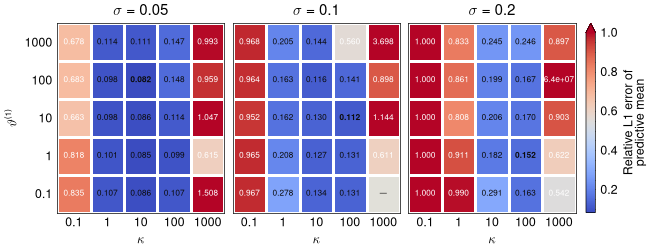

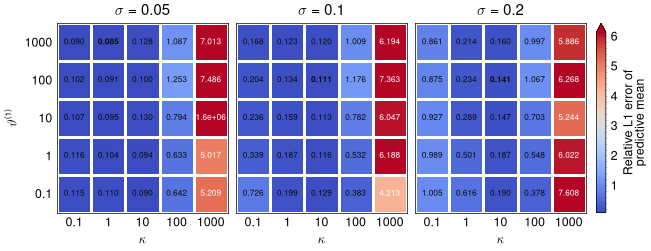

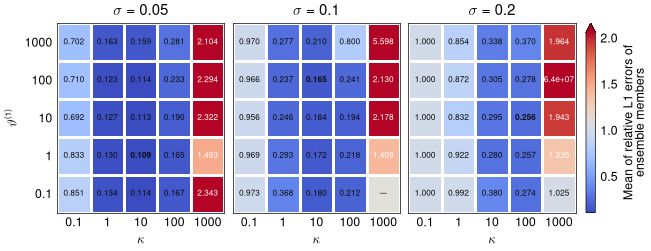

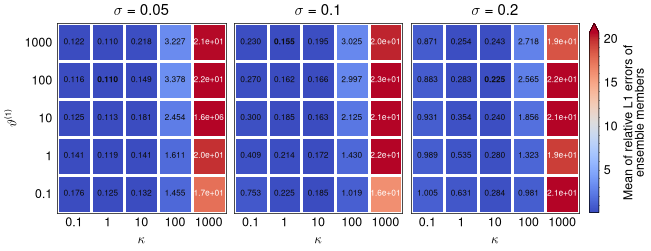

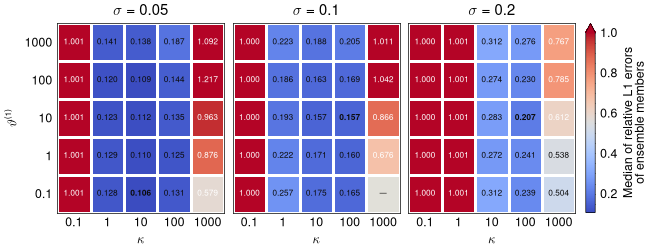

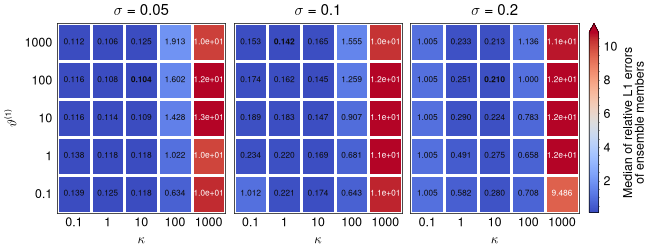

In [12]:
import textwrap
measure_slug = {error_measures[0]: 'RelL1PredMean', error_measures[1]: 'RelL1MembersMean', error_measures[2]: 'RelL1MembersMedian'}
vmax_quantile = 0.9
savefig = True

for measure in error_measures:
    for beta_ in beta_vec_cmp:
        values = np.concatenate([errors[measure][beta_, noise_].ravel() for noise_ in noise_vec_cmp])
        values = values[np.isfinite(values)]
        vmin, vmax = values.min(), max(np.quantile(values, vmax_quantile), values.min() + 1e-12)

        fig, axs = plt.subplots(1, len(noise_vec_cmp), figsize=(6.5, 2.5), sharey=True, constrained_layout=True)
        for ax, noise_ in zip(axs, noise_vec_cmp):
            Z = errors[measure][beta_, noise_]
            mesh = ax.pcolormesh(np.ma.masked_invalid(Z), cmap='coolwarm', vmin=vmin, vmax=vmax, edgecolors='white', linewidth=1)
            ax.set_facecolor('#e1e0d9')          # missing runs show as grey cells
            ax.grid(False, which='both'); ax.tick_params(which='both', length=0)
            ax.set_xticks(np.arange(len(kappa_vec_cmp)) + 0.5, [f'{c:g}' for c in kappa_vec_cmp])
            ax.set_yticks(np.arange(len(vartheta1_vec_cmp)) + 0.5, [f'{v:g}' for v in vartheta1_vec_cmp])
            ax.set_xlabel(r'$\kappa$'); ax.set_title(rf'$\sigma = {noise_:g}$')
            best = np.unravel_index(np.nanargmin(Z), Z.shape) if np.isfinite(Z).any() else None
            for i in range(len(vartheta1_vec_cmp)):
                for j in range(len(kappa_vec_cmp)):
                    if not np.isfinite(Z[i, j]):
                        ax.text(j + 0.5, i + 0.5, '--', ha='center', va='center', color='#52514e')
                        continue
                    label = f'{Z[i, j]:.3f}' if abs(Z[i, j]) < 10 else f'{Z[i, j]:.1e}'   # blown-up configurations get a compact exponent
                    if (i, j) == best and mpl.rcParams['text.usetex']:   # usetex ignores fontweight
                        label = rf'\textbf{{{label}}}'
                    ax.text(j + 0.5, i + 0.5, label, ha='center', va='center', fontsize=6,
                            color='white' if mesh.norm(Z[i, j]) > 0.5 else '#0b0b0b', fontweight='bold' if (i, j) == best else 'normal')
        axs[0].set_ylabel(r'$\vartheta^{(1)}$')
        cbar = fig.colorbar(mesh, ax=axs.tolist(), fraction=0.03, pad=0.02, extend='max' if values.max() > vmax else 'neither')
        cbar.set_label('\n'.join(textwrap.wrap(measure, 30)))

        if savefig == True:
            os.makedirs(os.path.join(fig_dirname, model_name), exist_ok=True)
            fig.savefig(os.path.join(fig_dirname, f'{model_name}/{initializer}_{optimizer_name}_beta{beta_}_{measure_slug[measure]}_vartheta1_cscale_table.pdf'))
        fig.show()

### Stability Analysis

In [ ]:
def stability(model_name, noise_, initializer, vartheta1_vec, kappa_vec, beta_=1.0, savefig=False):
    fig, axs = plt.subplots()

    # Load the results
    for vartheta1_ in vartheta1_vec:
        rel_l1_of_mean_vec = []
        mean_of_rel_l1_errors_vec = []
        median_of_rel_l1_errors_vec = []
        for kappa_ in kappa_vec:
            if model_name == 'Gaussian':
                model_list = [GaussianBNN(**common, gauss_std=1.0) for _ in range(N_ENSEMBLES)]
                filename = lambda i: os.path.join(dirname, f'{model_name}/{initializer}/{optimizer_name}_noise_{noise_}/Ensemble_{i}/{model_name}_model_{i}.csv')
            elif model_name == 'Cauchy':
                model_list = [CauchyBNN(**common, cauchy_scale=1.0) for _ in range(N_ENSEMBLES)]
                filename = lambda i: os.path.join(dirname, f'{model_name}/{initializer}/{optimizer_name}_noise_{noise_}/Ensemble_{i}/{model_name}_model_{i}.csv')
            elif model_name == 'GSBL_Independent':
                model_list = [GSBLBNN(**common, vartheta1=vartheta1_, kappa=kappa_, c_bias=c_bias, n_inner=n_inner, r=r, beta=beta_) for _ in range(N_ENSEMBLES)]
                filename = lambda i: os.path.join(dirname, f'{model_name}/{initializer}/{optimizer_name}_kappa{kappa_}_beta{beta_}_vartheta1_{vartheta1_}_noise_{noise_}/Ensemble_{i}/{model_name}_model_{i}.csv')
            elif model_name == 'GSBL_Shared':
                model_list = [GSBLBNN(**common, vartheta1=vartheta1_, kappa=kappa_, c_bias=c_bias, n_inner=n_inner, r=r, beta=beta_) for _ in range(N_ENSEMBLES)]
                filename = lambda i: os.path.join(dirname, f'{model_name}/{initializer}/{optimizer_name}_kappa{kappa_}_beta{beta_}_vartheta1_{vartheta1_}_noise_{noise_}/Ensemble_{i}/{model_name}_model_{i}.csv')
            else:
                raise ValueError(f"Unknown model name: {model_name}")
            for i, model in enumerate(model_list):
                    model.load(filename(i))
            
            # Predict on interior grid and calculate relative L1 error for each ensemble member
            y_pred_interpolation = jnp.stack([model.evaluate(x_fine) for model in model_list], axis=0)
            rel_l1_mask = jnp.sum(jnp.abs(y_pred_interpolation - f(x_fine)), axis=1) / jnp.sum(jnp.abs(f(x_fine)), axis=0)

            # Mask which ensembles to throw away (the worst performing ones)
            mask = jnp.argsort(rel_l1_mask.reshape(-1))[:N_ENSEMBLES]

            # Only take those ensembles that are not thrown away
            model_list = [model_list[i] for i in mask]
            y_pred_extrapolation = jnp.stack([model.evaluate(x_extrapolation) for model in model_list], axis=0)
            y_pred_interpolation = y_pred_interpolation[mask]
            predictive_mean_interpolation = jnp.mean(y_pred_interpolation, axis=0)
            rel_l1_of_mean = jnp.sum(jnp.abs(predictive_mean_interpolation - f(x_fine))) / jnp.sum(jnp.abs(f(x_fine)))
            mean_of_rel_l1_errors = jnp.mean(rel_l1_mask[mask])
            median_of_rel_l1_errors = jnp.median(rel_l1_mask[mask])

            rel_l1_of_mean_vec.append(rel_l1_of_mean)
            mean_of_rel_l1_errors_vec.append(mean_of_rel_l1_errors)
            median_of_rel_l1_errors_vec.append(median_of_rel_l1_errors)

        axs.semilogx(kappa_vec, mean_of_rel_l1_errors_vec, label=f'vartheta1={vartheta1}', marker='s')


    axs.grid(True)
    axs.set_xlabel('kappa'); axs.set_ylabel('Mean of relative L1 errors')
    axs.legend()

    fig.tight_layout()
    if savefig == True:
        if model_name in ['GSBL_Independent', 'GSBL_Shared']:
            fig.savefig(os.path.join(fig_dirname, f'{model_name}/{initializer}_{optimizer_name}_beta{beta_}_noise_{noise_}_stability_plot.pdf'))
        else:
            fig.savefig(os.path.join(fig_dirname, f'{model_name}/{initializer}_{optimizer_name}_noise_{noise_}_stability_plot.pdf'))
    fig.show()

# Piecewise-Smooth Function

In [8]:
# Problem 03
def f(x):
    test_fcn_smooth = lambda x: jnp.sin(x * 2 * jnp.pi)
    y = jnp.where(x < 0.2, test_fcn_smooth(x), 
            jnp.where(x < 0.7, test_fcn_smooth(x+0.55), -0.5)
        )
    return y

# Parameter
M = 50
n_disc = 128
kernel_width = 0.03
SEED = 42

# Data generation -- the data key is INDEPENDENT of the network init key
data_key = jr.PRNGKey(SEED + 1000)
x_disc = jnp.linspace(0.0, 1.0, n_disc).reshape(-1, 1)
x_obs = jnp.linspace(0.0, 1.0, M).reshape(-1, 1)
x_extrapolation = jnp.linspace(-0.2, 1.2, 1_000).reshape(-1, 1)

F = build_F(x_obs, x_disc, kernel_width)
y_true = f(x_disc)

# For plotting and evaluation only
x_fine = jnp.linspace(0.0, 1.0, 1000).reshape(-1, 1)
y_fine = f(x_fine)
y_blur_fine = build_F(x_fine, x_disc, kernel_width) @ y_true

y_obs_vec = []
for noise in noise_level:
    y_obs = F @ y_true + noise * jr.normal(data_key, (M, 1))
    y_obs_vec.append(y_obs)

In [9]:
dirname = 'out/PiecewiseSmooth_Blur/'
fig_dirname = 'out/figures/PiecewiseSmooth_Blur/'
if not os.path.exists(fig_dirname):
    os.makedirs(fig_dirname)

Model: Gaussian, Noise: 0.05, Relative L1 error of predictive mean: 0.157015, Mean of relative L1 errors of ensemble members: 0.163438, Median of relative L1 errors of ensemble members: 0.155183, Median of wall clock times: 8.534725, Variance of relative L1 errors of ensemble members: 0.000562, CRPS: 0.080198
Model: Cauchy, Noise: 0.05, Relative L1 error of predictive mean: 0.142241, Mean of relative L1 errors of ensemble members: 0.150750, Median of relative L1 errors of ensemble members: 0.143767, Median of wall clock times: 8.812005, Variance of relative L1 errors of ensemble members: 0.000695, CRPS: 0.068098
Model: GSBL_Shared, Noise: 0.05, Relative L1 error of predictive mean: 0.120685, Mean of relative L1 errors of ensemble members: 0.210916, Median of relative L1 errors of ensemble members: 0.180708, Median of wall clock times: 8.999575, Variance of relative L1 errors of ensemble members: 0.015332, CRPS: 0.052964
Panel size: 2.019 x 1.615 in


/var/folders/mm/p6fstv8949vbtxn89ljjbk8w0000gp/T/ipykernel_37305/2725333759.py:33: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


Panel size: 2.019 x 1.615 in
Model: Gaussian, Noise: 0.1, Relative L1 error of predictive mean: 0.197202, Mean of relative L1 errors of ensemble members: 0.208081, Median of relative L1 errors of ensemble members: 0.194547, Median of wall clock times: 8.440405, Variance of relative L1 errors of ensemble members: 0.001745, CRPS: 0.103901
Model: Cauchy, Noise: 0.1, Relative L1 error of predictive mean: 0.862815, Mean of relative L1 errors of ensemble members: 0.871740, Median of relative L1 errors of ensemble members: 0.888121, Median of wall clock times: 8.792035, Variance of relative L1 errors of ensemble members: 0.006862, CRPS: 0.488396
Model: GSBL_Shared, Noise: 0.1, Relative L1 error of predictive mean: 0.148488, Mean of relative L1 errors of ensemble members: 0.248615, Median of relative L1 errors of ensemble members: 0.232258, Median of wall clock times: 9.039619, Variance of relative L1 errors of ensemble members: 0.004106, CRPS: 0.069006
Panel size: 2.019 x 1.615 in
Panel size:

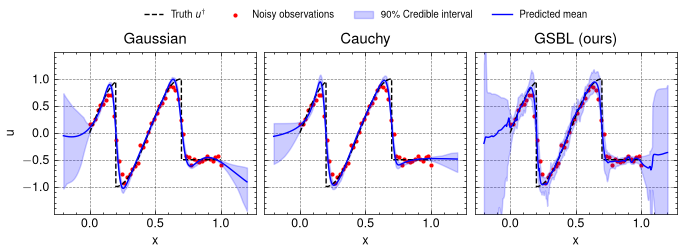

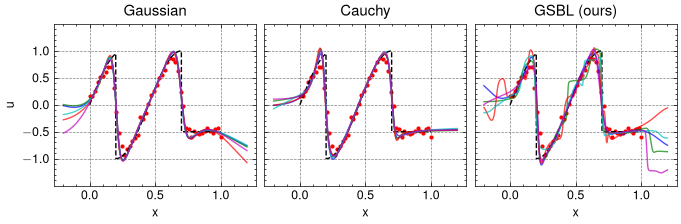

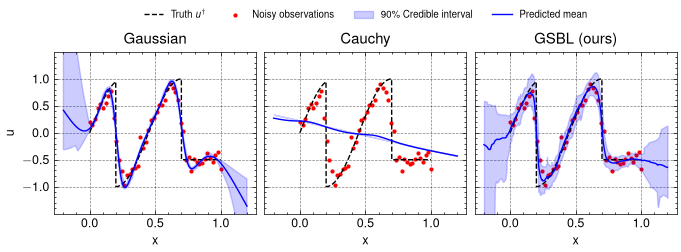

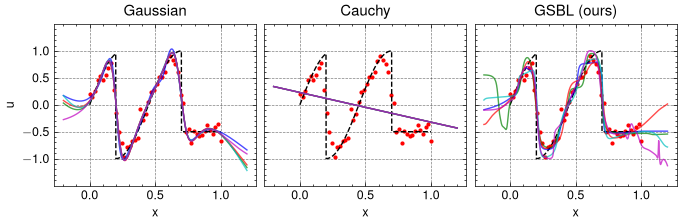

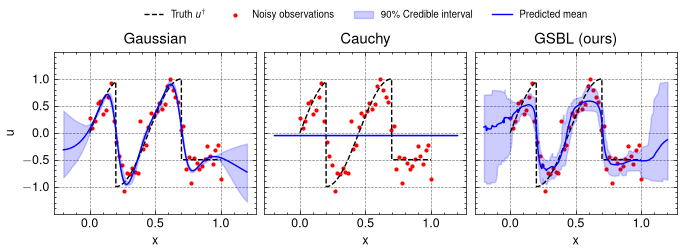

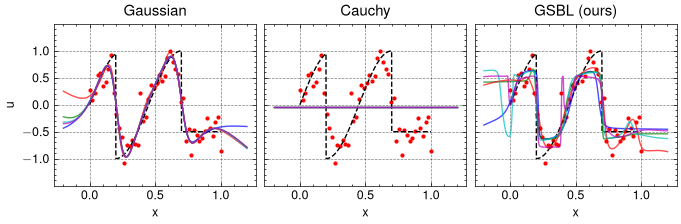

In [10]:
col_titles = ['Gaussian', 'Cauchy', 'GSBL (ours)']

for noise in [0.05, 0.1, 0.2]:
    # Comparison figure: Gaussian vs. Cauchy vs. shared GSBL, one call per panel fills both grids
    fig_band, axs_band = make_grid(1, 3)
    fig_member, axs_member = make_grid(1, 3)
    plot_routine('Gaussian', noise, initializer='Default', ax_band=axs_band[0, 0], ax_member=axs_member[0, 0])
    plot_routine('Cauchy', noise, initializer='Default', ax_band=axs_band[0, 1], ax_member=axs_member[0, 1])
    plot_routine('GSBL_Shared', noise, initializer='GG', vartheta1_=vartheta1, kappa_=kappa, beta_=1.0, ax_band=axs_band[0, 2], ax_member=axs_member[0, 2])
    finish_grid(fig_band, axs_band, col_titles=col_titles, legend_ncol=4, savefig=True, filename=os.path.join(fig_dirname, f'{optimizer_name}_noise_{noise}_CompareBNNs_credibility_band.pdf'))
    finish_grid(fig_member, axs_member, col_titles=col_titles, savefig=True, filename=os.path.join(fig_dirname, f'{optimizer_name}_noise_{noise}_CompareBNNs_member_plots.pdf'))


### Coverage

<>:36: SyntaxWarning: invalid escape sequence '\s'
<>:36: SyntaxWarning: invalid escape sequence '\s'
/var/folders/mm/p6fstv8949vbtxn89ljjbk8w0000gp/T/ipykernel_37305/1168487771.py:36: SyntaxWarning: invalid escape sequence '\s'
  axs.plot(coverage_level, coverage_vec, marker[index_noise], color=colors[index_noise], label=f'$\sigma={noise_}$')


Model: GSBL_Shared, Noise: 0.05, MSE of coverage: 0.034196
Model: GSBL_Shared, Noise: 0.1, MSE of coverage: 0.025919
Model: GSBL_Shared, Noise: 0.2, MSE of coverage: 0.033161


/var/folders/mm/p6fstv8949vbtxn89ljjbk8w0000gp/T/ipykernel_37305/1168487771.py:47: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


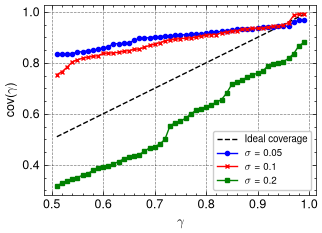

In [11]:
beta = 1.0
Cauchy_initializer = 'Default'
savefig = True

colors = ['b', 'r', 'g']
marker = ['-o', '-x', '-s']

coverage_level = jnp.linspace(0.51, 0.99, 49)
fig, axs = plt.subplots(figsize=(6.8/2, 2.5))
axs.plot(coverage_level, coverage_level, '--', color='black', label='Ideal coverage')
model_name = 'GSBL_Shared'

# for noise_ in [0.01, 0.05, 0.1, 0.2]:
for index_noise, noise_ in enumerate([0.05, 0.1, 0.2]):
    initializer = Cauchy_initializer if model_name == 'Cauchy' else 'GG'

    quantile_05_rel_l1_errors_vec, quantile_95_rel_l1_errors_vec = [], []
    coverage_vec = []
    model_list = [GSBLBNN(**common, vartheta1=vartheta1, kappa=kappa, c_bias=c_bias, n_inner=n_inner, r=r, beta=beta) for _ in range(N_ENSEMBLES)]
    filename = lambda i: os.path.join(dirname, f'{model_name}/{initializer}/{optimizer_name}_kappa{kappa}_beta{beta}_vartheta1_{vartheta1}_noise_{noise_}/Ensemble_{i}/{model_name}_model_{i}.csv')

    for i, model in enumerate(model_list):
        model.load(filename(i))

    for level in coverage_level:

        # Predict on interior grid and calculate relative L1 error for each ensemble member
        y_pred_interpolation = jnp.stack([model.evaluate(x_fine) for model in model_list], axis=0)


        lo, hi = (1 - level) / 2, 1 - (1 - level) / 2
        q_lo, q_hi = jnp.quantile(y_pred_interpolation, lo, axis=0), jnp.quantile(y_pred_interpolation, hi, axis=0)
        covered = (y_fine >= q_lo) & (y_fine <= q_hi)
        coverage_vec.append(jnp.mean(covered))

    axs.plot(coverage_level, coverage_vec, marker[index_noise], color=colors[index_noise], label=f'$\sigma={noise_}$')

    mse_coverage = jnp.mean((jnp.array(coverage_vec) - coverage_level) ** 2)
    print(f"Model: {model_name}, Noise: {noise_}, MSE of coverage: {mse_coverage:.6f}")

axs.legend()
axs.set_xlabel('$\\gamma$'); axs.set_ylabel(f'$\\mathrm{{cov}}(\\gamma)$'); axs.grid(True)

fig.tight_layout()
if savefig == True:
    fig.savefig(os.path.join(fig_dirname, f'Coverage_GSBL_Shared.pdf'))
fig.show()